# Titanic Survival Prediction using Machine Learning
**Mini Project - Machine Learning**

## 1. Problem Statement
The Titanic ship sank in 1912 and many passengers died. In this project we use **machine learning to predict whether a
passenger survived or not**, using details like gender, age, ticket class and fare.

## 2. Type of Machine Learning: Supervised Learning
- **Supervised learning** = we train the model on data where the **correct answer is already known**.
- Here the correct answer is the column `Survived` (1 = survived, 0 = died). This column is called the **target / label**.
- The other columns (Sex, Age, Pclass ...) are called **features**.
- The model learns the pattern between features and the target, then predicts for new passengers.
- Because the answer is one of two classes (0 or 1), this is **Classification** (a type of supervised learning).

**Steps we follow:** Load data -> Clean data -> Explore (graphs) -> Split into train/test -> Train models -> Compare -> Predict

## 3. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## 4. Load the Dataset

In [2]:
df = pd.read_csv("titanic_raw.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Columns:** Survived (target), Pclass (ticket class 1/2/3), Name, Sex, Age, SibSp (siblings/spouse aboard),
Parch (parents/children aboard), Ticket, Fare (ticket price), Cabin, Embarked (port: S/C/Q).

## 5. Data Cleaning

### Step 1: Check missing values

In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

- **Age** has 177 missing values -> fill with the **median age**.
- **Embarked** has 2 missing -> fill with the **most common port**.
- **Cabin** has 687 missing (too many) -> **drop** this column.
- **PassengerId, Name, Ticket** are just identifiers and do not help prediction -> **drop**.

In [4]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### Step 2: Convert text to numbers
Machine learning models understand only numbers, so we convert:
- Sex: male = 0, female = 1
- Embarked: S = 0, C = 1, Q = 2

In [5]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["Embarked"] = df["Embarked"].map({"S": 0, "C": 1, "Q": 2})

# Save the cleaned data
clean = df.drop(columns=["PassengerId", "Name", "Ticket"])
clean.to_csv("titanic_analysis.csv", index=False)
clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0


## 6. Exploratory Data Analysis (Graphs)

/tmp/ipykernel_87/2818712789.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Survived", palette=["#D9534F", "#4C9F70"])


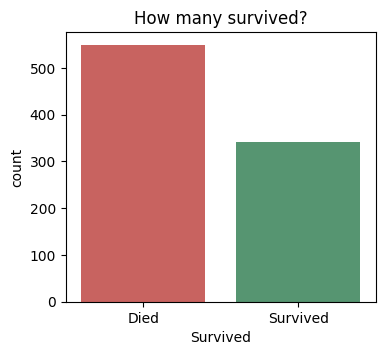

Survived
0    62.0
1    38.0
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(4, 3.5))
sns.countplot(data=df, x="Survived", palette=["#D9534F", "#4C9F70"])
plt.xticks([0, 1], ["Died", "Survived"])
plt.title("How many survived?")
plt.show()
print(df["Survived"].value_counts(normalize=True).round(2) * 100)

/tmp/ipykernel_87/3016401949.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sex", y="Survived", ax=ax[0], palette="Set2")
/tmp/ipykernel_87/3016401949.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(["Male", "Female"]); ax[0].set_title("Survival rate by Gender")
/tmp/ipykernel_87/3016401949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[1], palette="Set2")


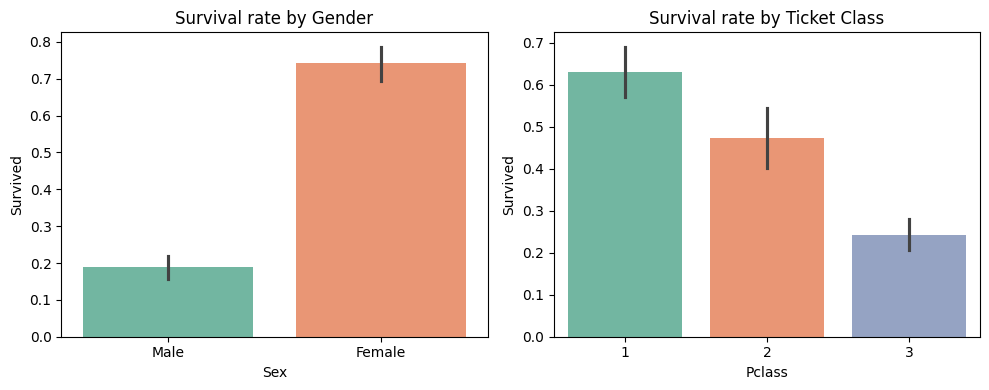

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x="Sex", y="Survived", ax=ax[0], palette="Set2")
ax[0].set_xticklabels(["Male", "Female"]); ax[0].set_title("Survival rate by Gender")
sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[1], palette="Set2")
ax[1].set_title("Survival rate by Ticket Class")
plt.tight_layout(); plt.show()

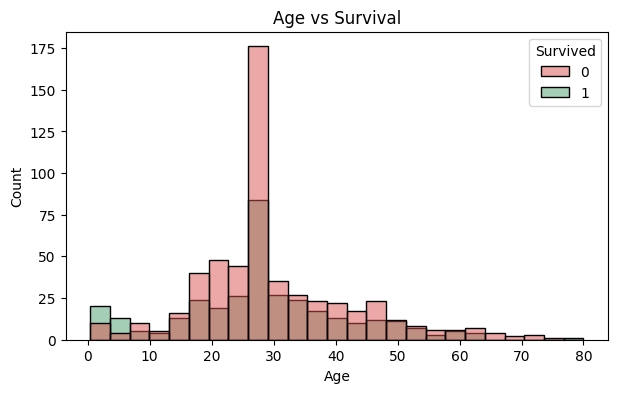

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, palette=["#D9534F", "#4C9F70"])
plt.title("Age vs Survival")
plt.show()

**What the graphs tell us**
- Only about **38%** of passengers survived.
- **Women survived much more than men** (about 74% vs 19%).
- **First class** passengers survived more than third class.
- **Children** had a better chance of survival.

## 7. Split Data into Train and Test
- **X** = features (inputs), **y** = target (answer).
- **80% training data**: the model learns from this.
- **20% testing data**: the model has never seen this; we use it to check how good the model is.

In [9]:
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 712 | Testing rows: 179


## 8. Train the Models (all Supervised Classification algorithms)
| Model | Simple idea |
|---|---|
| **Logistic Regression** | Draws a boundary line between survived and died using a mathematical formula |
| **Decision Tree** | Asks a series of Yes/No questions (like "Is the passenger female?") to reach a decision |
| **Random Forest** | Many decision trees vote together; the majority answer wins |
| **AdaBoost** | Boosting: builds many **weak learners** one after another (here each weak learner is a *decision stump*, a tree with only 1 question, `max_depth=1`). Each new stump focuses on the passengers the earlier ones got wrong, and all stumps are combined by a weighted vote |

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    # weak learner = decision stump (tree with only 1 question); 50 stumps are built one after another
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=50, learning_rate=1.0, random_state=42),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)          # learn from training data
    pred = model.predict(X_test)         # predict on unseen test data
    predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(4).sort_values(["Accuracy", "F1-Score"], ascending=False).reset_index(drop=True)
results.to_csv("model_comparison.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.8268,0.8116,0.7568,0.7832
1,Logistic Regression,0.7989,0.7714,0.7297,0.7500
2,AdaBoost,0.7989,0.7879,0.7027,0.7429
3,Decision Tree,0.7989,0.8393,0.6351,0.7231


**Metrics in simple words**
- **Accuracy**: out of all passengers, how many did the model predict correctly?
- **Precision**: when the model says "survived", how often is it right?
- **Recall**: out of all who really survived, how many did the model find?
- **F1-Score**: one number that balances precision and recall.
- If two models have the **same accuracy**, we pick the one with the higher F1-score.

/tmp/ipykernel_87/1628797658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x="Accuracy", y="Model", palette="Blues_r")


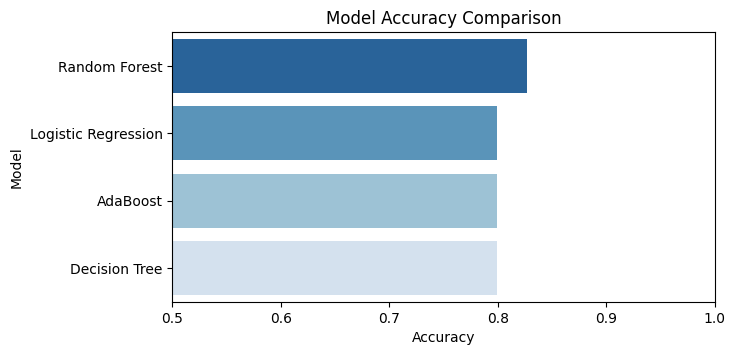

In [11]:
plt.figure(figsize=(7, 3.5))
sns.barplot(data=results, x="Accuracy", y="Model", palette="Blues_r")
plt.xlim(0.5, 1); plt.title("Model Accuracy Comparison")
plt.show()

## 9. Best Model and Confusion Matrix

Best model: Random Forest | Accuracy: 0.8268


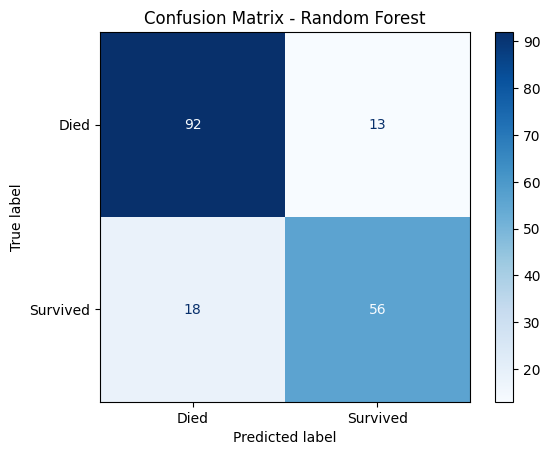

In [12]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name, "| Accuracy:", results.loc[0, "Accuracy"])

ConfusionMatrixDisplay.from_predictions(y_test, predictions[best_name],
                                        display_labels=["Died", "Survived"], cmap="Blues")
plt.title("Confusion Matrix - " + best_name)
plt.show()

**How to read the confusion matrix:** top-left and bottom-right are the **correct** predictions;
the other two boxes are the **mistakes**.

## 10. Decision Tree Diagram
A decision tree is easy to explain because we can *see* the questions it asks.
(Shown with depth 3 to keep it readable.)

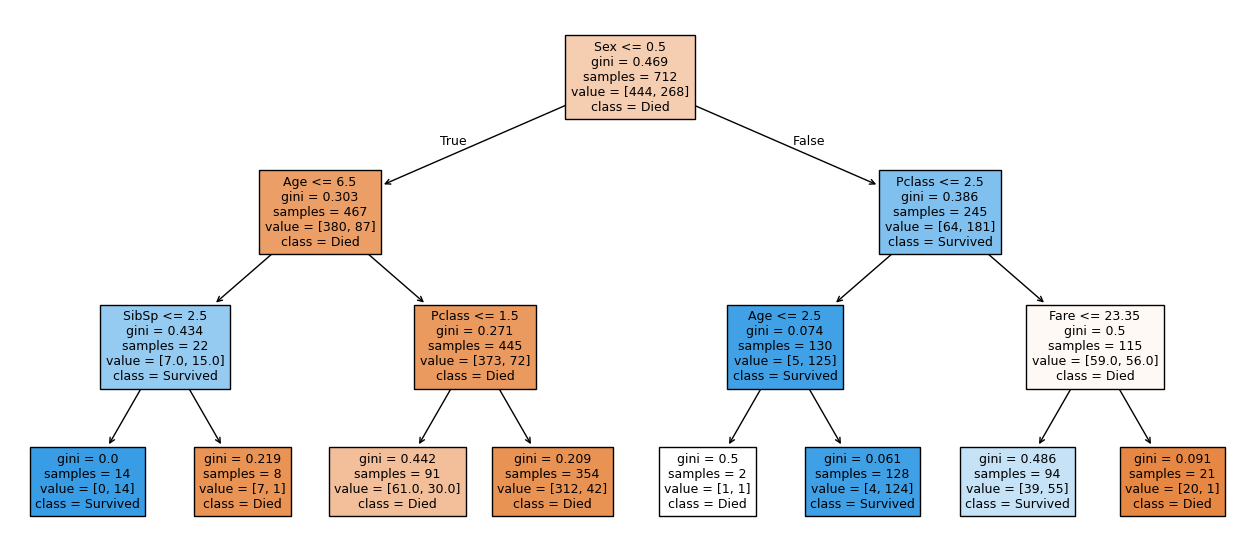

In [13]:
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(small_tree, feature_names=X.columns, class_names=["Died", "Survived"], filled=True, fontsize=9)
plt.show()

## 11. Which features matter most? (Random Forest)

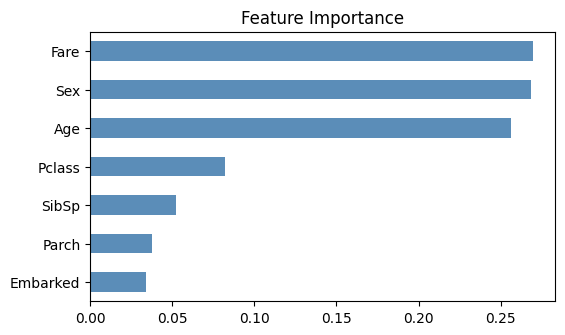

In [14]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="#5B8DB8", figsize=(6, 3.5), title="Feature Importance")
plt.show()

## 12. Effect of `n_estimators` and the Weak Learner
**Weak learner** = a very simple model that is only slightly better than guessing. AdaBoost combines many weak learners into one strong model.
In this project the weak learner is a **decision stump**: `DecisionTreeClassifier(max_depth=1)`, a tree that asks only ONE question.

**`n_estimators`** = how many models are built inside the ensemble:
- **AdaBoost:** number of weak learners (stumps) built one after another.
- **Random Forest:** number of full decision trees built independently.
- **Decision Tree and Logistic Regression** are single models, so they have no `n_estimators`. For a Decision Tree the similar setting is `max_depth`.

Below we train both ensembles with different values of `n_estimators` and watch the train and test accuracy.

In [15]:
n_list = [1, 5, 10, 25, 50, 100, 200, 500]
rows = []
for n in n_list:
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                             n_estimators=n, random_state=42).fit(X_train, y_train)
    rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
    rows.append({"n_estimators": n,
                 "AdaBoost Train": ada.score(X_train, y_train), "AdaBoost Test": ada.score(X_test, y_test),
                 "RandomForest Train": rf.score(X_train, y_train), "RandomForest Test": rf.score(X_test, y_test)})

n_results = pd.DataFrame(rows).round(4)
n_results

,n_estimators,AdaBoost Train,AdaBoost Test,RandomForest Train,RandomForest Test
0,1,0.7879,0.7821,0.8876,0.7765
1,5,0.8048,0.7989,0.9508,0.7989
2,10,0.8048,0.7989,0.9579,0.8101
3,25,0.8132,0.7933,0.9761,0.8156
4,50,0.8146,0.7989,0.9789,0.8212
5,100,0.8160,0.7933,0.9789,0.8268
6,200,0.8174,0.8101,0.9789,0.8212
7,500,0.8329,0.8045,0.9789,0.8156


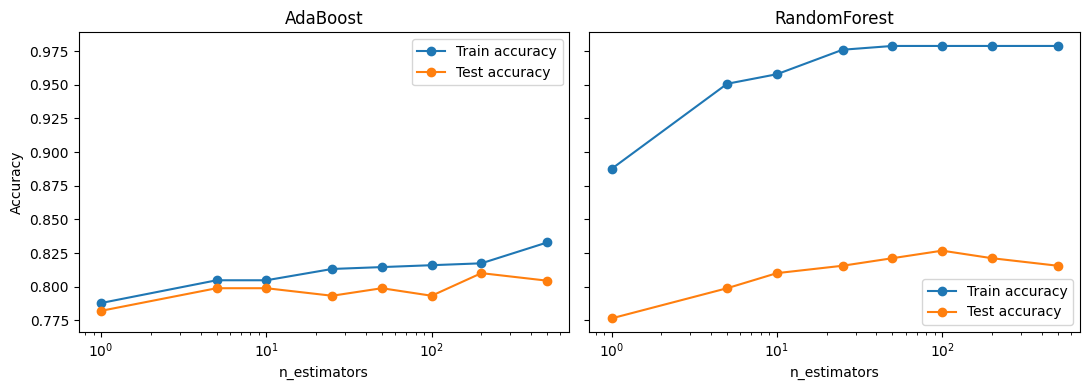

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, name in zip(ax, ["AdaBoost", "RandomForest"]):
    a.plot(n_results["n_estimators"], n_results[name + " Train"], marker="o", label="Train accuracy")
    a.plot(n_results["n_estimators"], n_results[name + " Test"], marker="o", label="Test accuracy")
    a.set_xscale("log"); a.set_xlabel("n_estimators"); a.set_title(name); a.legend()
ax[0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

**What happens when `n_estimators` is increased or decreased**
- **Too few (for example 1):** AdaBoost with 1 stump is just one single question (about 78% test accuracy). Random Forest with 1 tree is just one decision tree. Both are weak and unstable.
- **Increasing it:** accuracy improves quickly in the beginning and then **flattens**. Adding more models after that gives almost no benefit but costs more training time.
- **AdaBoost:** train accuracy rises slowly (0.79 to 0.83) and test accuracy stays around 0.80, so it overfits slowly because each stump is very simple.
- **Random Forest:** train accuracy jumps to about 0.98 very early because each tree is fully grown, while test accuracy stays around 0.82. More trees do **not** make Random Forest overfit more, they only make the vote more stable.
- Test accuracy moves up and down a little between values because the test set has only 179 passengers.

In [17]:
# What if the weak learner is NOT a stump? (AdaBoost, 50 rounds)
rows = []
for d in [1, 2, 3, 5, None]:
    ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=d),
                             n_estimators=50, random_state=42).fit(X_train, y_train)
    rows.append({"Weak learner max_depth": d if d else "None (full tree)",
                 "Train": ada.score(X_train, y_train), "Test": ada.score(X_test, y_test)})
pd.DataFrame(rows).round(4)

,Weak learner max_depth,Train,Test
0,1,0.8146,0.7989
1,2,0.8483,0.8156
2,3,0.8764,0.8156
3,5,0.9649,0.7933
4,None (full tree),0.9789,0.7765


**Why the weak learner must stay weak:** with a stump or a very shallow tree (depth 1 to 3) AdaBoost works well. When the weak learner becomes a deep or full tree, the training accuracy goes to about 0.98 while the test accuracy drops (about 0.78 for a full tree) because every learner already memorises the training data, so there is nothing left for boosting to improve.

In [18]:
# For a single Decision Tree the similar setting is max_depth
rows = []
for d in [1, 2, 3, 4, 6, 8, None]:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"Decision Tree max_depth": d if d else "None (full tree)",
                 "Train": dt.score(X_train, y_train), "Test": dt.score(X_test, y_test)})
pd.DataFrame(rows).round(4)

,Decision Tree max_depth,Train,Test
0,1,0.7879,0.7821
1,2,0.8034,0.7654
2,3,0.8343,0.7989
3,4,0.8399,0.7989
4,6,0.8666,0.8045
5,8,0.8989,0.7933
6,None (full tree),0.9789,0.7989


A deeper tree keeps increasing the train accuracy (up to about 0.98) but the test accuracy stays at about 0.79 to 0.80. This growing gap between train and test accuracy is **overfitting**, and it is the reason `max_depth=4` was used for the Decision Tree.

## 13. Save Predictions

In [19]:
out = df.loc[X_test.index, ["PassengerId", "Name"]].copy()
out["Actual"] = y_test.map({0: "Died", 1: "Survived"})
out["Predicted"] = pd.Series(predictions[best_name], index=X_test.index).map({0: "Died", 1: "Survived"})
out["Correct"] = (out["Actual"] == out["Predicted"]).map({True: "Yes", False: "No"})
out = out.sort_values("PassengerId").reset_index(drop=True)
out.to_csv("survival_predictions.csv", index=False)
print("Correct predictions:", (out["Correct"] == "Yes").sum(), "out of", len(out))
out.head(10)

Correct predictions: 148 out of 179


,PassengerId,Name,Actual,Predicted,Correct
0,6,"Moran, Mr. James",Died,Died,Yes
1,11,"Sandstrom, Miss. Marguerite Rut",Survived,Survived,Yes
2,24,"Sloper, Mr. William Thompson",Survived,Survived,Yes
3,26,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",Survived,Died,No
4,31,"Uruchurtu, Don. Manuel E",Died,Died,Yes
5,32,"Spencer, Mrs. William Augustus (Marie Eugenie)",Survived,Survived,Yes
6,34,"Wheadon, Mr. Edward H",Died,Survived,No
7,40,"Nicola-Yarred, Miss. Jamila",Survived,Died,No
8,45,"Devaney, Miss. Margaret Delia",Survived,Died,No
9,50,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",Died,Died,Yes


## 14. Predict for a New Passenger

In [20]:
def predict_passenger(pclass, sex, age, sibsp, parch, fare, embarked):
    # sex: "male"/"female" | embarked: "S"/"C"/"Q"
    row = pd.DataFrame([[pclass, 0 if sex == "male" else 1, age, sibsp, parch, fare,
                         {"S": 0, "C": 1, "Q": 2}[embarked]]], columns=X.columns)
    return "Survived" if best_model.predict(row)[0] == 1 else "Died"

print("1st class woman, age 28 :", predict_passenger(1, "female", 28, 0, 0, 80, "S"))
print("3rd class man, age 30   :", predict_passenger(3, "male", 30, 0, 0, 8, "S"))
print("2nd class girl, age 8   :", predict_passenger(2, "female", 8, 1, 1, 26, "S"))

1st class woman, age 28 : Survived
3rd class man, age 30   : Died
2nd class girl, age 8   : Survived


## 15. Conclusion
- We used **supervised learning (classification)** to predict Titanic survival from passenger details.
- Four models were trained and tested on 179 unseen passengers:
  - **Random Forest: 82.7% accuracy (best)** - 148 of 179 predictions correct, F1-score 0.78
  - Logistic Regression: 79.9% accuracy, F1-score 0.75
  - AdaBoost (weak learner = decision stump, 50 rounds): 79.9% accuracy, F1-score 0.74
  - Decision Tree: 79.9% accuracy, F1-score 0.72
- Three models are tied at 79.9% accuracy, so they are ranked by F1-score in the comparison table.
- **Gender, fare and age** were the most important features in the Random Forest. Gender had by far the strongest effect in the graphs: women survived far more than men ("women and children first"). Passenger class also mattered: first class survived more than third class.
- **`n_estimators` experiment:** in Random Forest the training accuracy reaches about 0.98 very early and the test accuracy flattens at about 0.82, so more trees only make the vote more stable. In AdaBoost the accuracy improves slowly with more stumps. AdaBoost needs a *weak* learner: a full tree as weak learner overfits (train 0.98, test 0.78).
- **Limitations:** the dataset is small (891 passengers) and the models were used with basic settings. With only 179 test passengers, a few passengers change the accuracy by a visible amount, so the gap between Random Forest and the others should not be over-interpreted.
- **Future work:** try more models (KNN, SVM), tune parameters with cross-validation, and add features such as family size and title from the name.